# Treino do detector de portas de refrigeração abertas

**Energia que dá Lucro · Applied Computer Vision · FIAP Global Solution 2026.2**

Este notebook faz o ajuste fino (fine-tuning) de um modelo YOLO11 para detectar quatro classes:
`geladeira_aberta`, `geladeira_fechada`, `freezer_aberto` e `freezer_fechado`.

Ele funciona de dois jeitos:

- **No seu computador**, com placa de vídeo NVIDIA. Abra o notebook a partir da pasta do projeto.
- **No Google Colab**. Em *Ambiente de execução > Alterar o tipo de ambiente*, escolha uma GPU.

Rode as células na ordem. Para treinar uma segunda versão depois de melhorar o conjunto de imagens,
troque `VERSAO` para `"v2"` na célula de treino e rode de novo: a última célula compara as versões.

## 1. Ambiente

In [ ]:
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

# Em alguns computadores com Windows existe a variável de sistema OPENSSL_ia32cap, que faz uma
# biblioteca usada pelo Ultralytics (polars) abortar com "Fatal Error: HW capability found".
# Removê-la só deste processo evita o problema e não altera nada no sistema.
os.environ.pop("OPENSSL_ia32cap", None)

NO_COLAB = "google.colab" in sys.modules
if NO_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    RAIZ = Path("/content/energia-acv")
else:
    # No computador, a raiz é a pasta do projeto: a que contém o config.yaml.
    RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists()), None)
    assert RAIZ is not None, "Abra este notebook a partir da pasta do projeto (a que tem o config.yaml)."
RAIZ.mkdir(parents=True, exist_ok=True)

import torch
import ultralytics

print("Pasta do projeto:", RAIZ)
print("Ultralytics", ultralytics.__version__, "· PyTorch", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: nenhuma GPU encontrada. O treino vai funcionar, mas bem mais devagar.")
    print("No computador, instale o PyTorch com CUDA (veja o README). No Colab, ative a GPU.")

Pasta do projeto: c:\Users\Natan\Documents\gs-energia\energia-acv
Ultralytics 8.4.210 · PyTorch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5070


## 2. Conjunto de imagens

Exporte o conjunto anotado no Roboflow no formato **YOLOv11** (arquivo .zip).

- **No computador:** descompacte o .zip em `data/dataset/`, de modo que exista `data/dataset/data.yaml`.
- **No Colab:** a célula abaixo pede o arquivo .zip.

A célula também cria um `data_local.yaml` com os caminhos corretos para esta máquina, porque os caminhos
que vêm no arquivo exportado costumam não funcionar fora do Roboflow.

In [2]:
import yaml

DATASET = RAIZ / "data" / "dataset"
if not (DATASET / "data.yaml").exists() and NO_COLAB:
    from google.colab import files

    print("Envie o arquivo .zip exportado do Roboflow (formato YOLOv11).")
    enviado = files.upload()
    DATASET.mkdir(parents=True, exist_ok=True)
    shutil.unpack_archive(next(iter(enviado)), DATASET)
assert (DATASET / "data.yaml").exists(), (
    f"Não encontrei {DATASET / 'data.yaml'}. Descompacte nessa pasta o conjunto exportado do Roboflow."
)

original = yaml.safe_load((DATASET / "data.yaml").read_text(encoding="utf-8"))
nomes = original["names"]
NOMES = list(nomes) if isinstance(nomes, list) else [nomes[k] for k in sorted(nomes)]

dados = {"path": DATASET.as_posix()}
for chave, pastas in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
    for pasta in pastas:
        if (DATASET / pasta / "images").exists():
            dados[chave] = f"{pasta}/images"
            break
assert "train" in dados and "val" in dados, "O conjunto precisa ter as pastas train/ e valid/, cada uma com images/ e labels/."
dados["names"] = dict(enumerate(NOMES))

DATA_YAML = DATASET / "data_local.yaml"
DATA_YAML.write_text(yaml.safe_dump(dados, allow_unicode=True, sort_keys=False), encoding="utf-8")
print("Classes:", NOMES)

# Os nomes das classes precisam ser iguais aos do config.yaml, que a aplicação usa.
arquivo_config = RAIZ / "config.yaml"
if arquivo_config.exists():
    esperadas = set(yaml.safe_load(arquivo_config.read_text(encoding="utf-8"))["classes"])
    if set(NOMES) != esperadas:
        print("ATENÇÃO: as classes do conjunto são diferentes das do config.yaml.")
        print("  Só no conjunto:", sorted(set(NOMES) - esperadas))
        print("  Só no config.yaml:", sorted(esperadas - set(NOMES)))

Classes: ['freezer_aberto', 'freezer_fechado', 'geladeira_aberta', 'geladeira_fechada']


### Quantas imagens e quantos exemplos de cada classe

Classes com poucos exemplos costumam ter resultado pior. Se uma classe tiver bem menos exemplos
que as outras, vale coletar mais imagens dela antes de treinar.

train:  990 imagens · freezer_aberto: 162 · freezer_fechado: 414 · geladeira_aberta: 402 · geladeira_fechada: 501
  val:   94 imagens · freezer_aberto: 7 · freezer_fechado: 51 · geladeira_aberta: 45 · geladeira_fechada: 44
 test:   48 imagens · freezer_aberto: 3 · freezer_fechado: 25 · geladeira_aberta: 19 · geladeira_fechada: 27


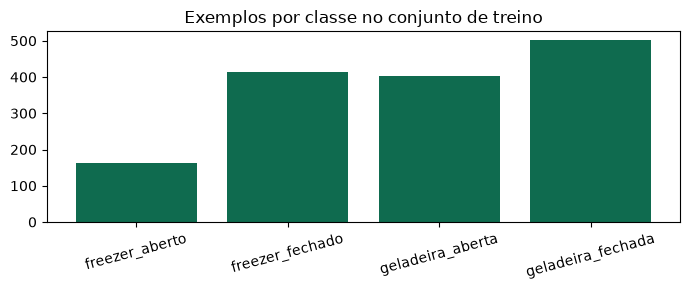

In [3]:
from collections import Counter

import matplotlib.pyplot as plt

contagens = {}
for chave in ("train", "val", "test"):
    if chave not in dados:
        continue
    pasta_imagens = DATASET / dados[chave]
    pasta_rotulos = pasta_imagens.parent / "labels"
    contagem = Counter()
    for arquivo in pasta_rotulos.glob("*.txt"):
        for linha in arquivo.read_text(encoding="utf-8").splitlines():
            if linha.strip():
                contagem[int(linha.split()[0])] += 1
    contagens[chave] = contagem
    total_imagens = sum(1 for _ in pasta_imagens.glob("*"))
    print(f"{chave:>5}: {total_imagens:4d} imagens · " + " · ".join(f"{NOMES[i]}: {contagem[i]}" for i in range(len(NOMES))))

plt.figure(figsize=(7, 3))
plt.bar(NOMES, [contagens["train"][i] for i in range(len(NOMES))], color="#0f6b4f")
plt.title("Exemplos por classe no conjunto de treino")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 3. Treino

Parte do modelo `yolo11n` (o menor e mais rápido da família), já treinado no conjunto COCO, e ajusta
os pesos para as nossas classes. O treino para sozinho se o resultado deixar de melhorar por 20 épocas.

In [4]:
from ultralytics import YOLO

VERSAO = "v1"                                   # troque para "v2" na segunda rodada
EPOCAS = int(os.environ.get("EPOCAS", 100))
TAMANHO = int(os.environ.get("TAMANHO_IMAGEM", 640))
TRABALHADORES = 0 if platform.system() == "Windows" else 8

modelo = YOLO("yolo11n.pt")
modelo.train(
    data=str(DATA_YAML),
    epochs=EPOCAS,
    imgsz=TAMANHO,
    batch=16,
    patience=20,
    seed=0,
    project=str(RAIZ / "runs"),
    name=f"porta_{VERSAO}",
    exist_ok=True,
    workers=TRABALHADORES,
)
PASTA_TREINO = Path(modelo.trainer.save_dir)
MELHOR = PASTA_TREINO / "weights" / "best.pt"
print("Melhores pesos:", MELHOR)

Ultralytics 8.4.210  Python-3.13.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\Natan\Documents\gs-energia\energia-acv\data\dataset\data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

## 4. Curvas de treino e matriz de confusão

- **results.png:** as perdas devem cair e as métricas subir ao longo das épocas.
- **Matriz de confusão:** mostra quais classes o modelo confunde entre si (por exemplo, porta entreaberta).

results.png


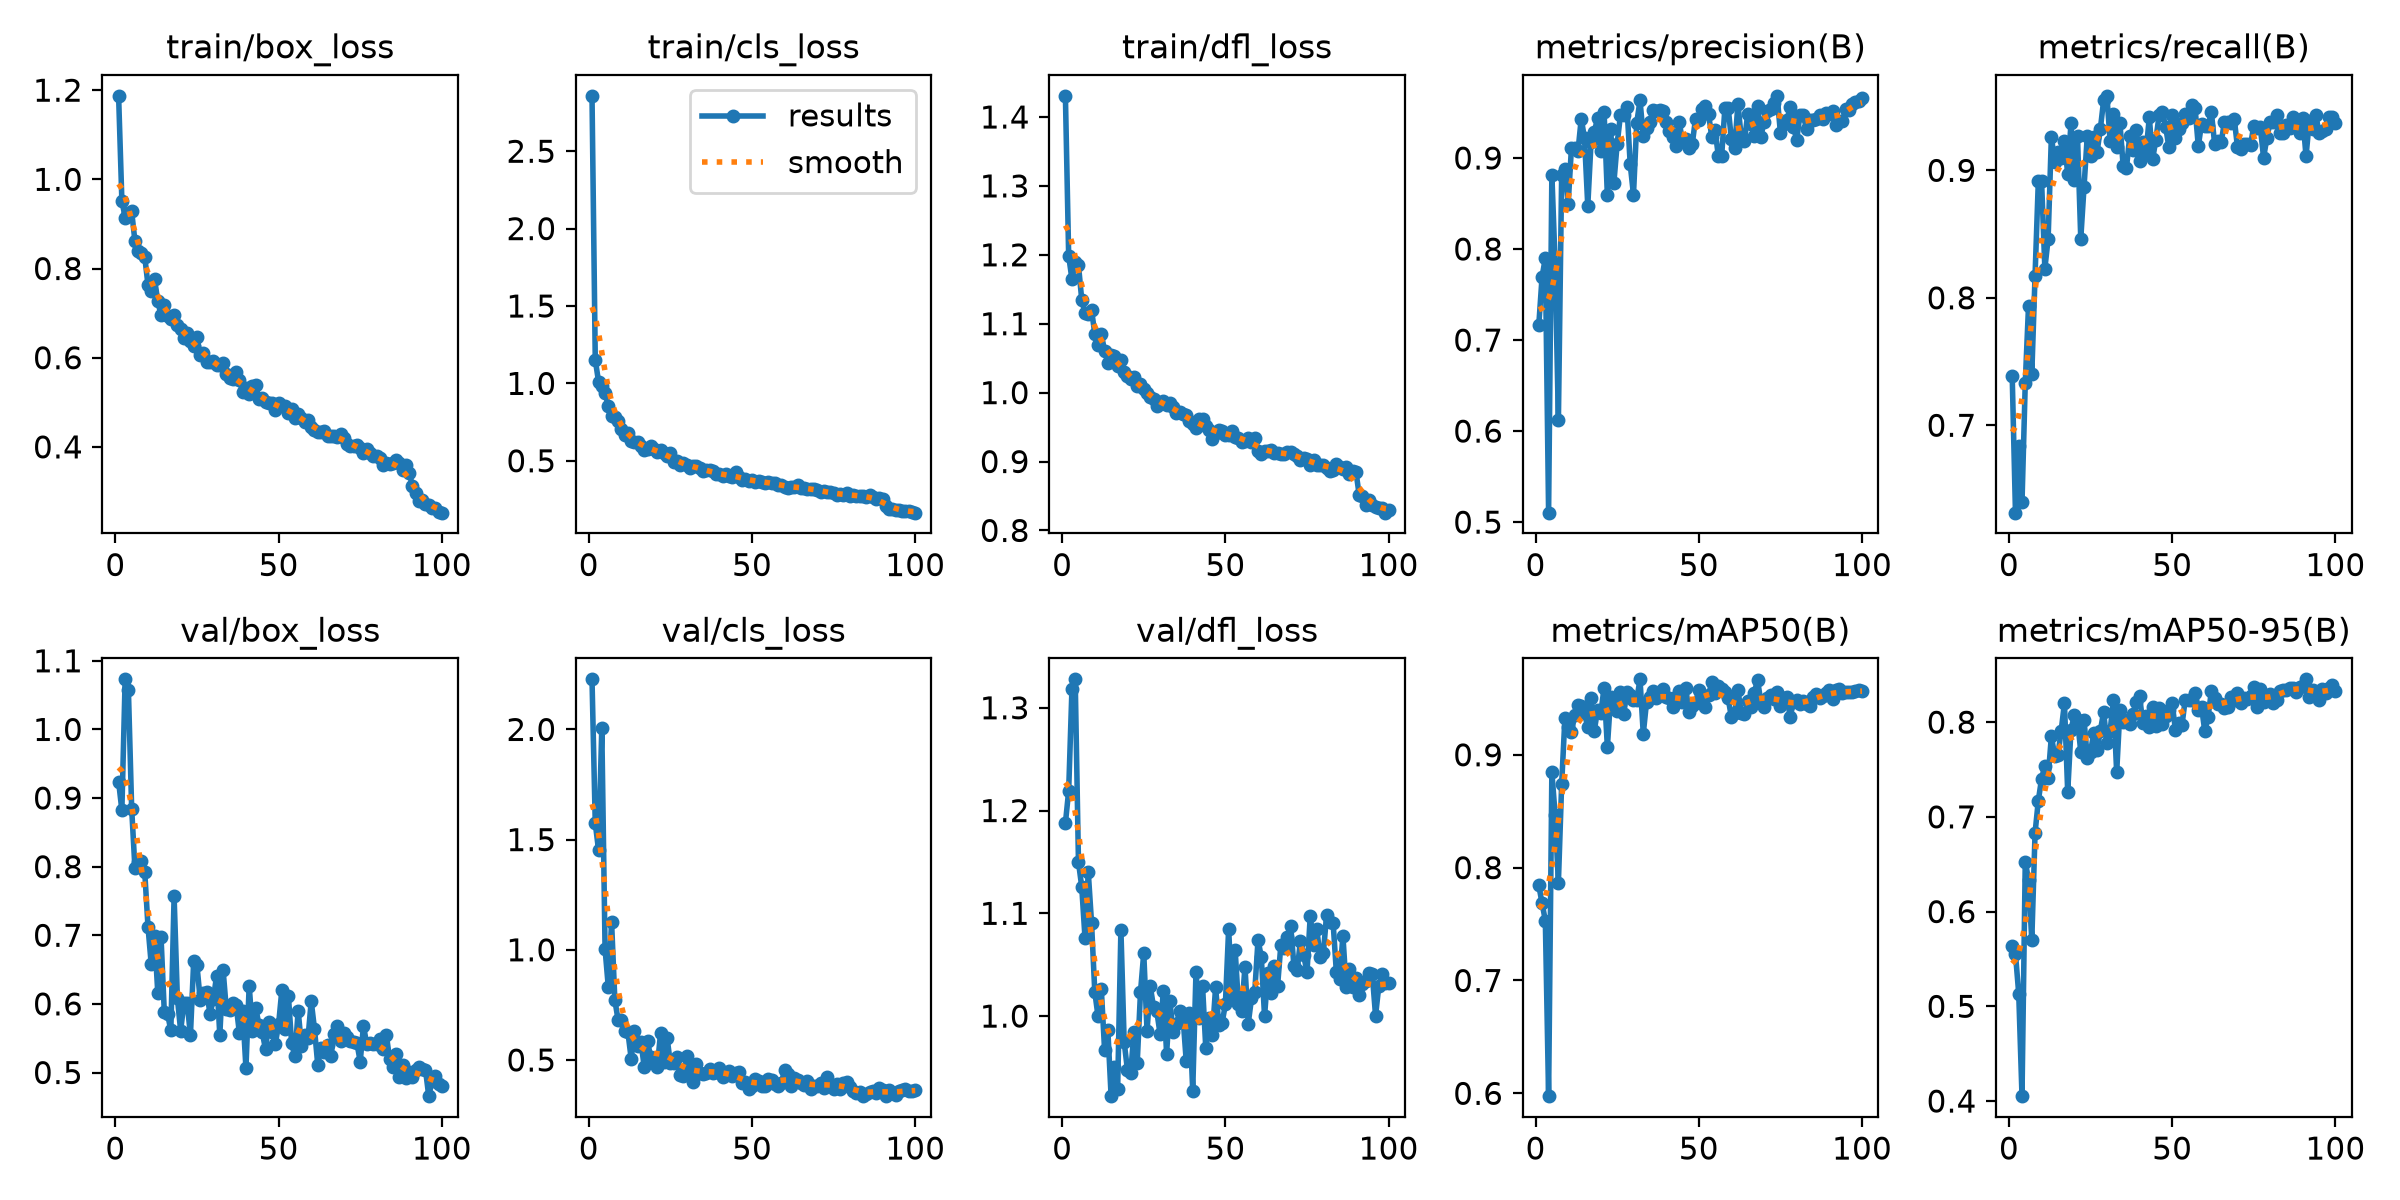

confusion_matrix_normalized.png


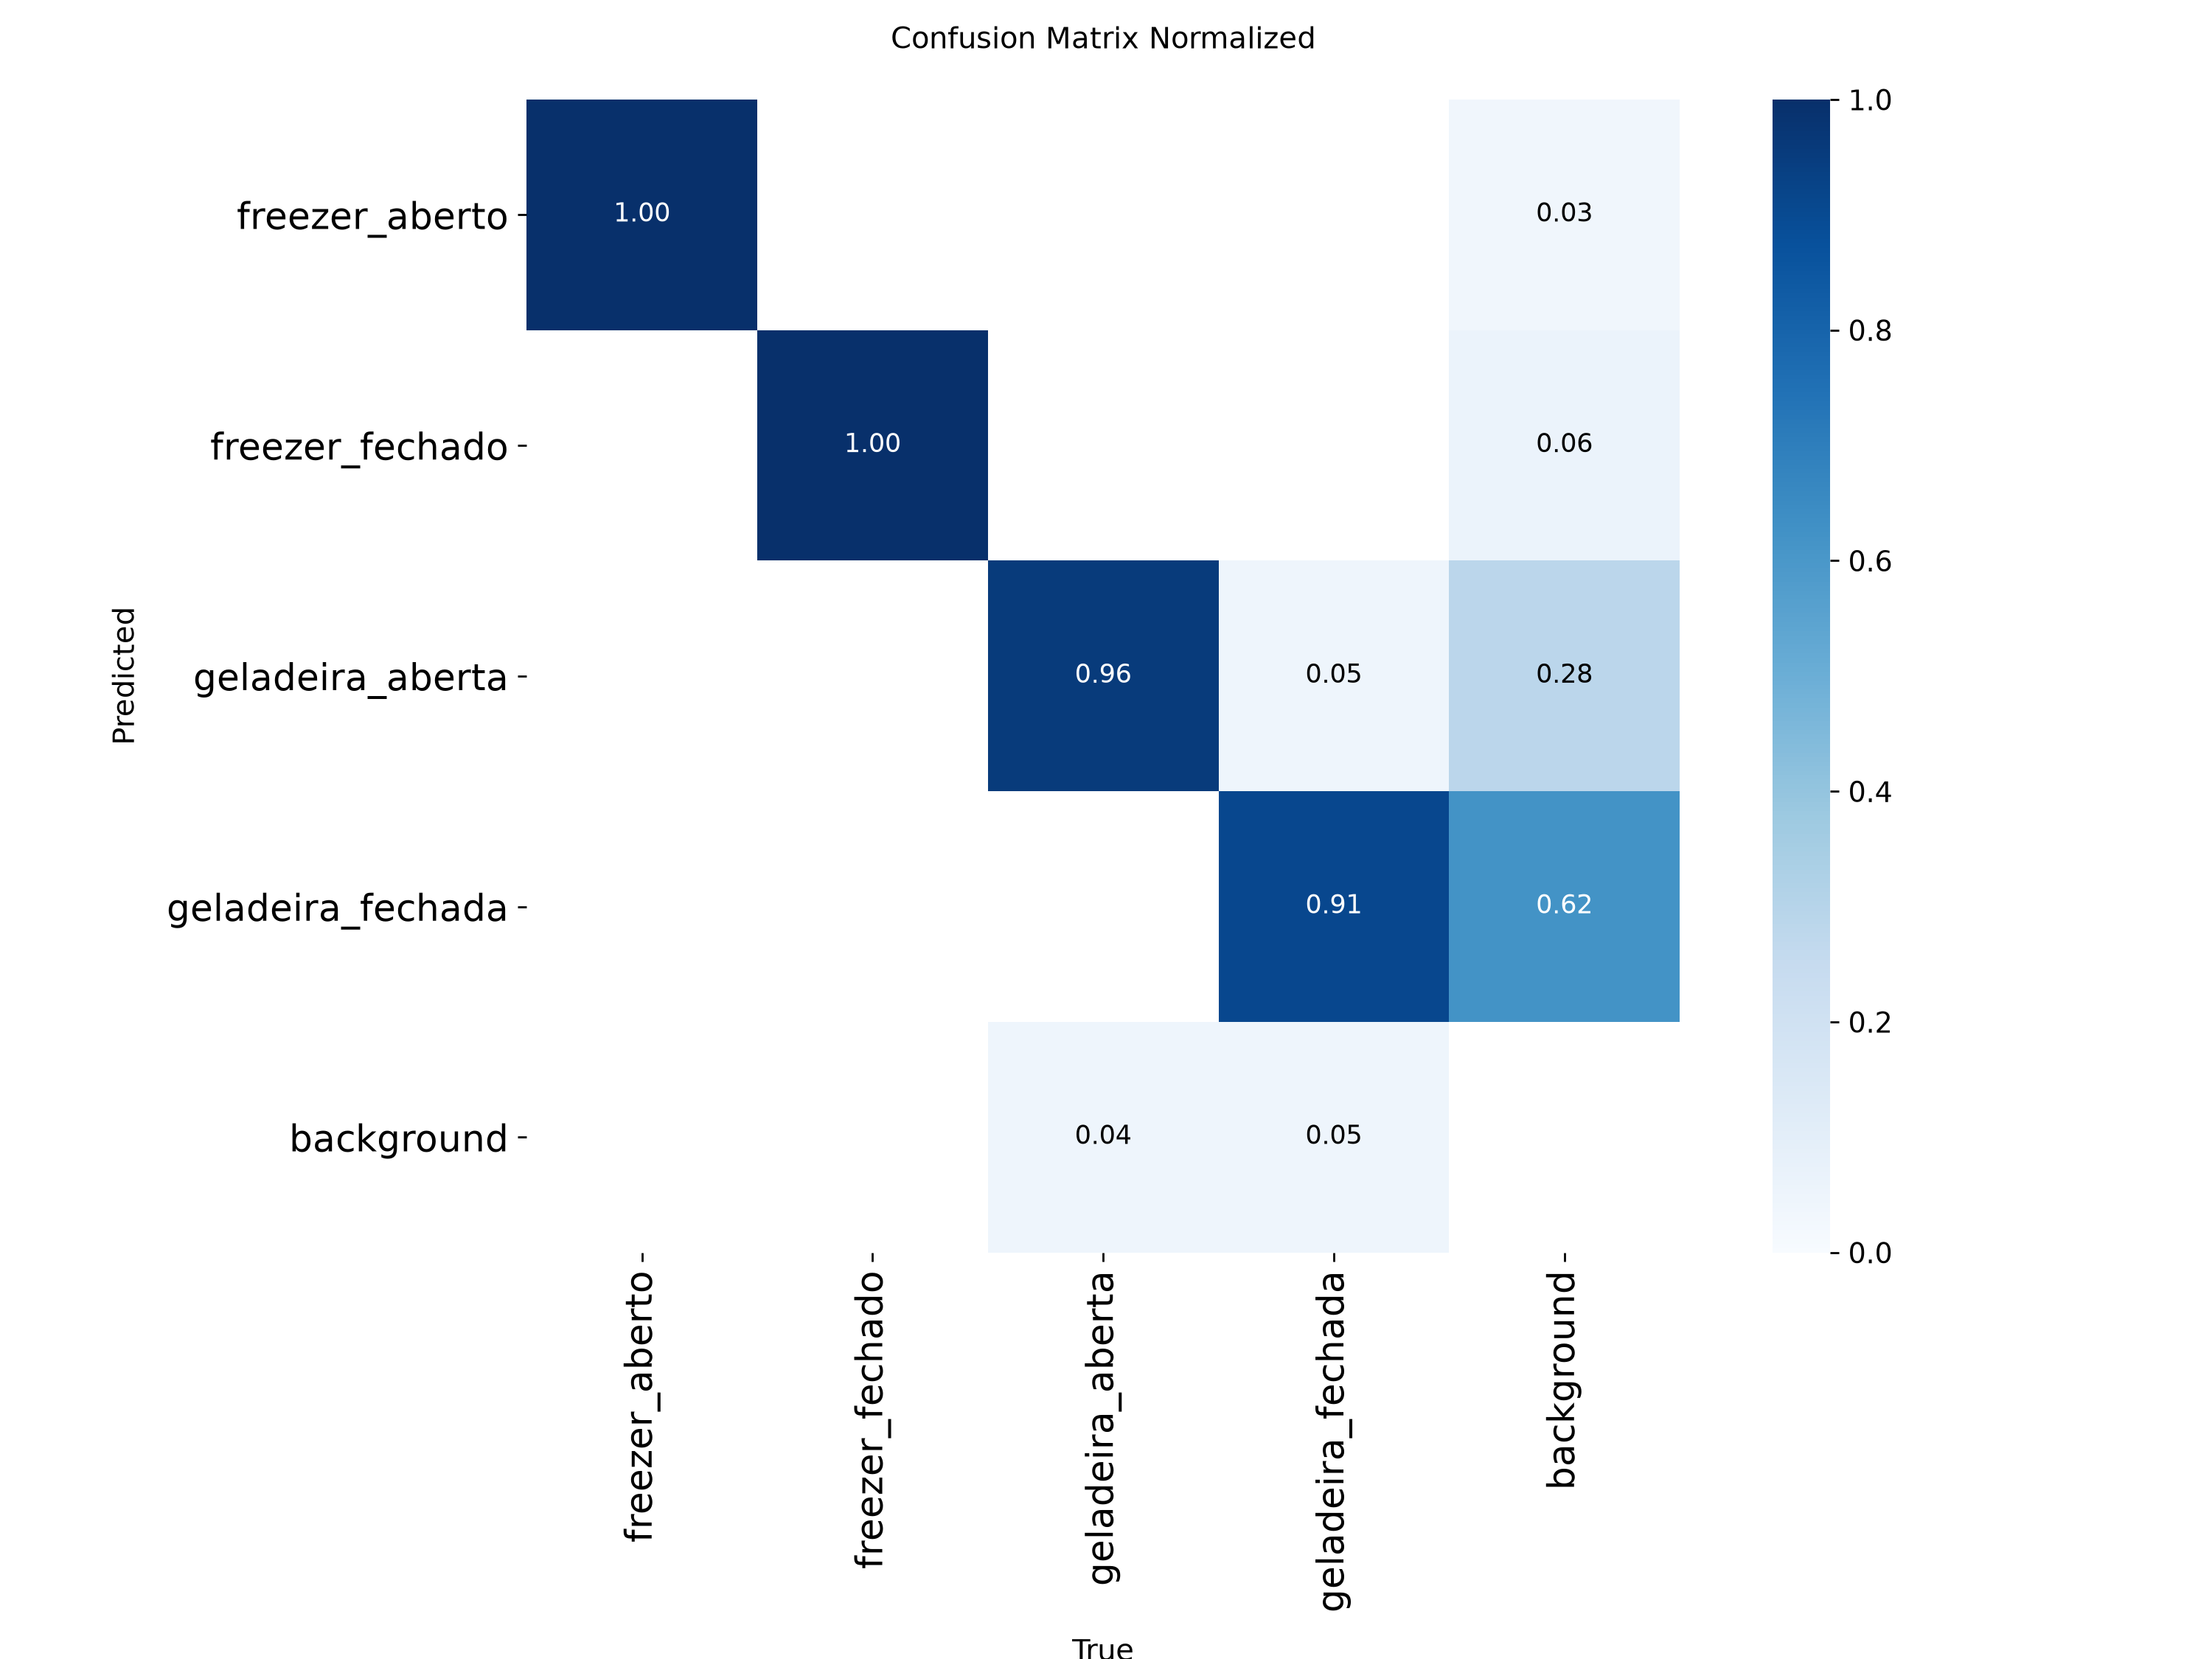

confusion_matrix.png


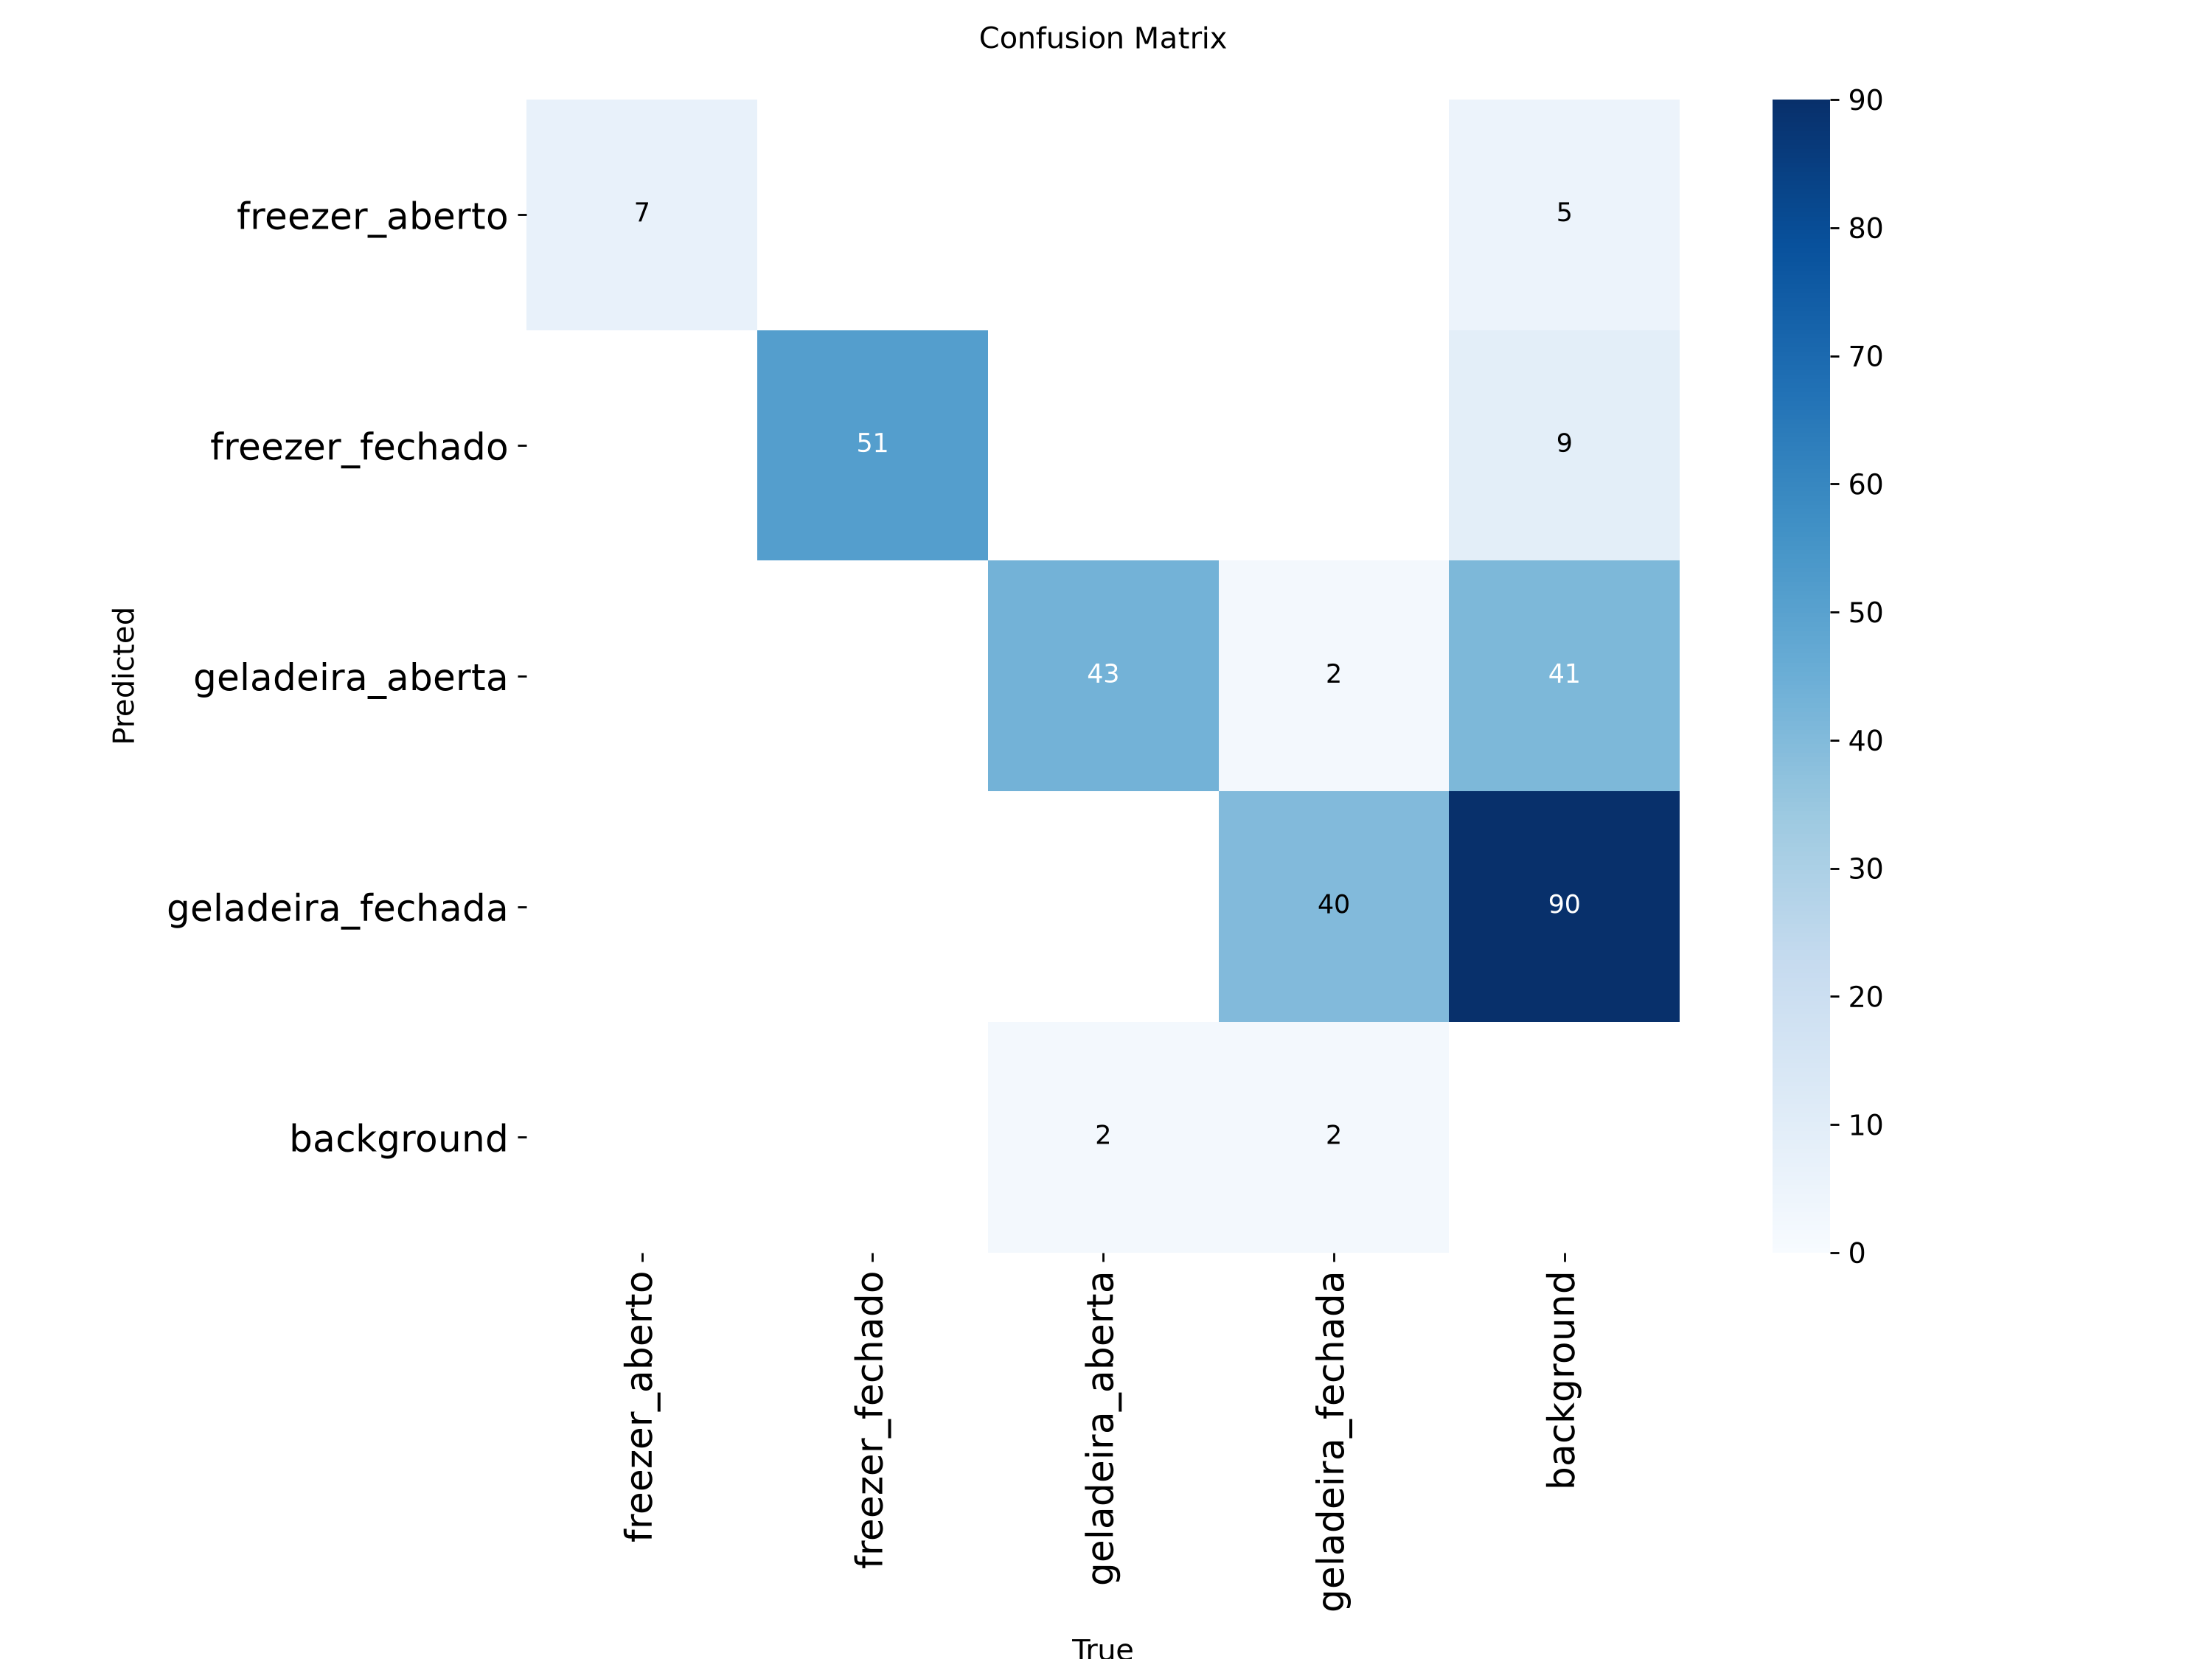

BoxPR_curve.png


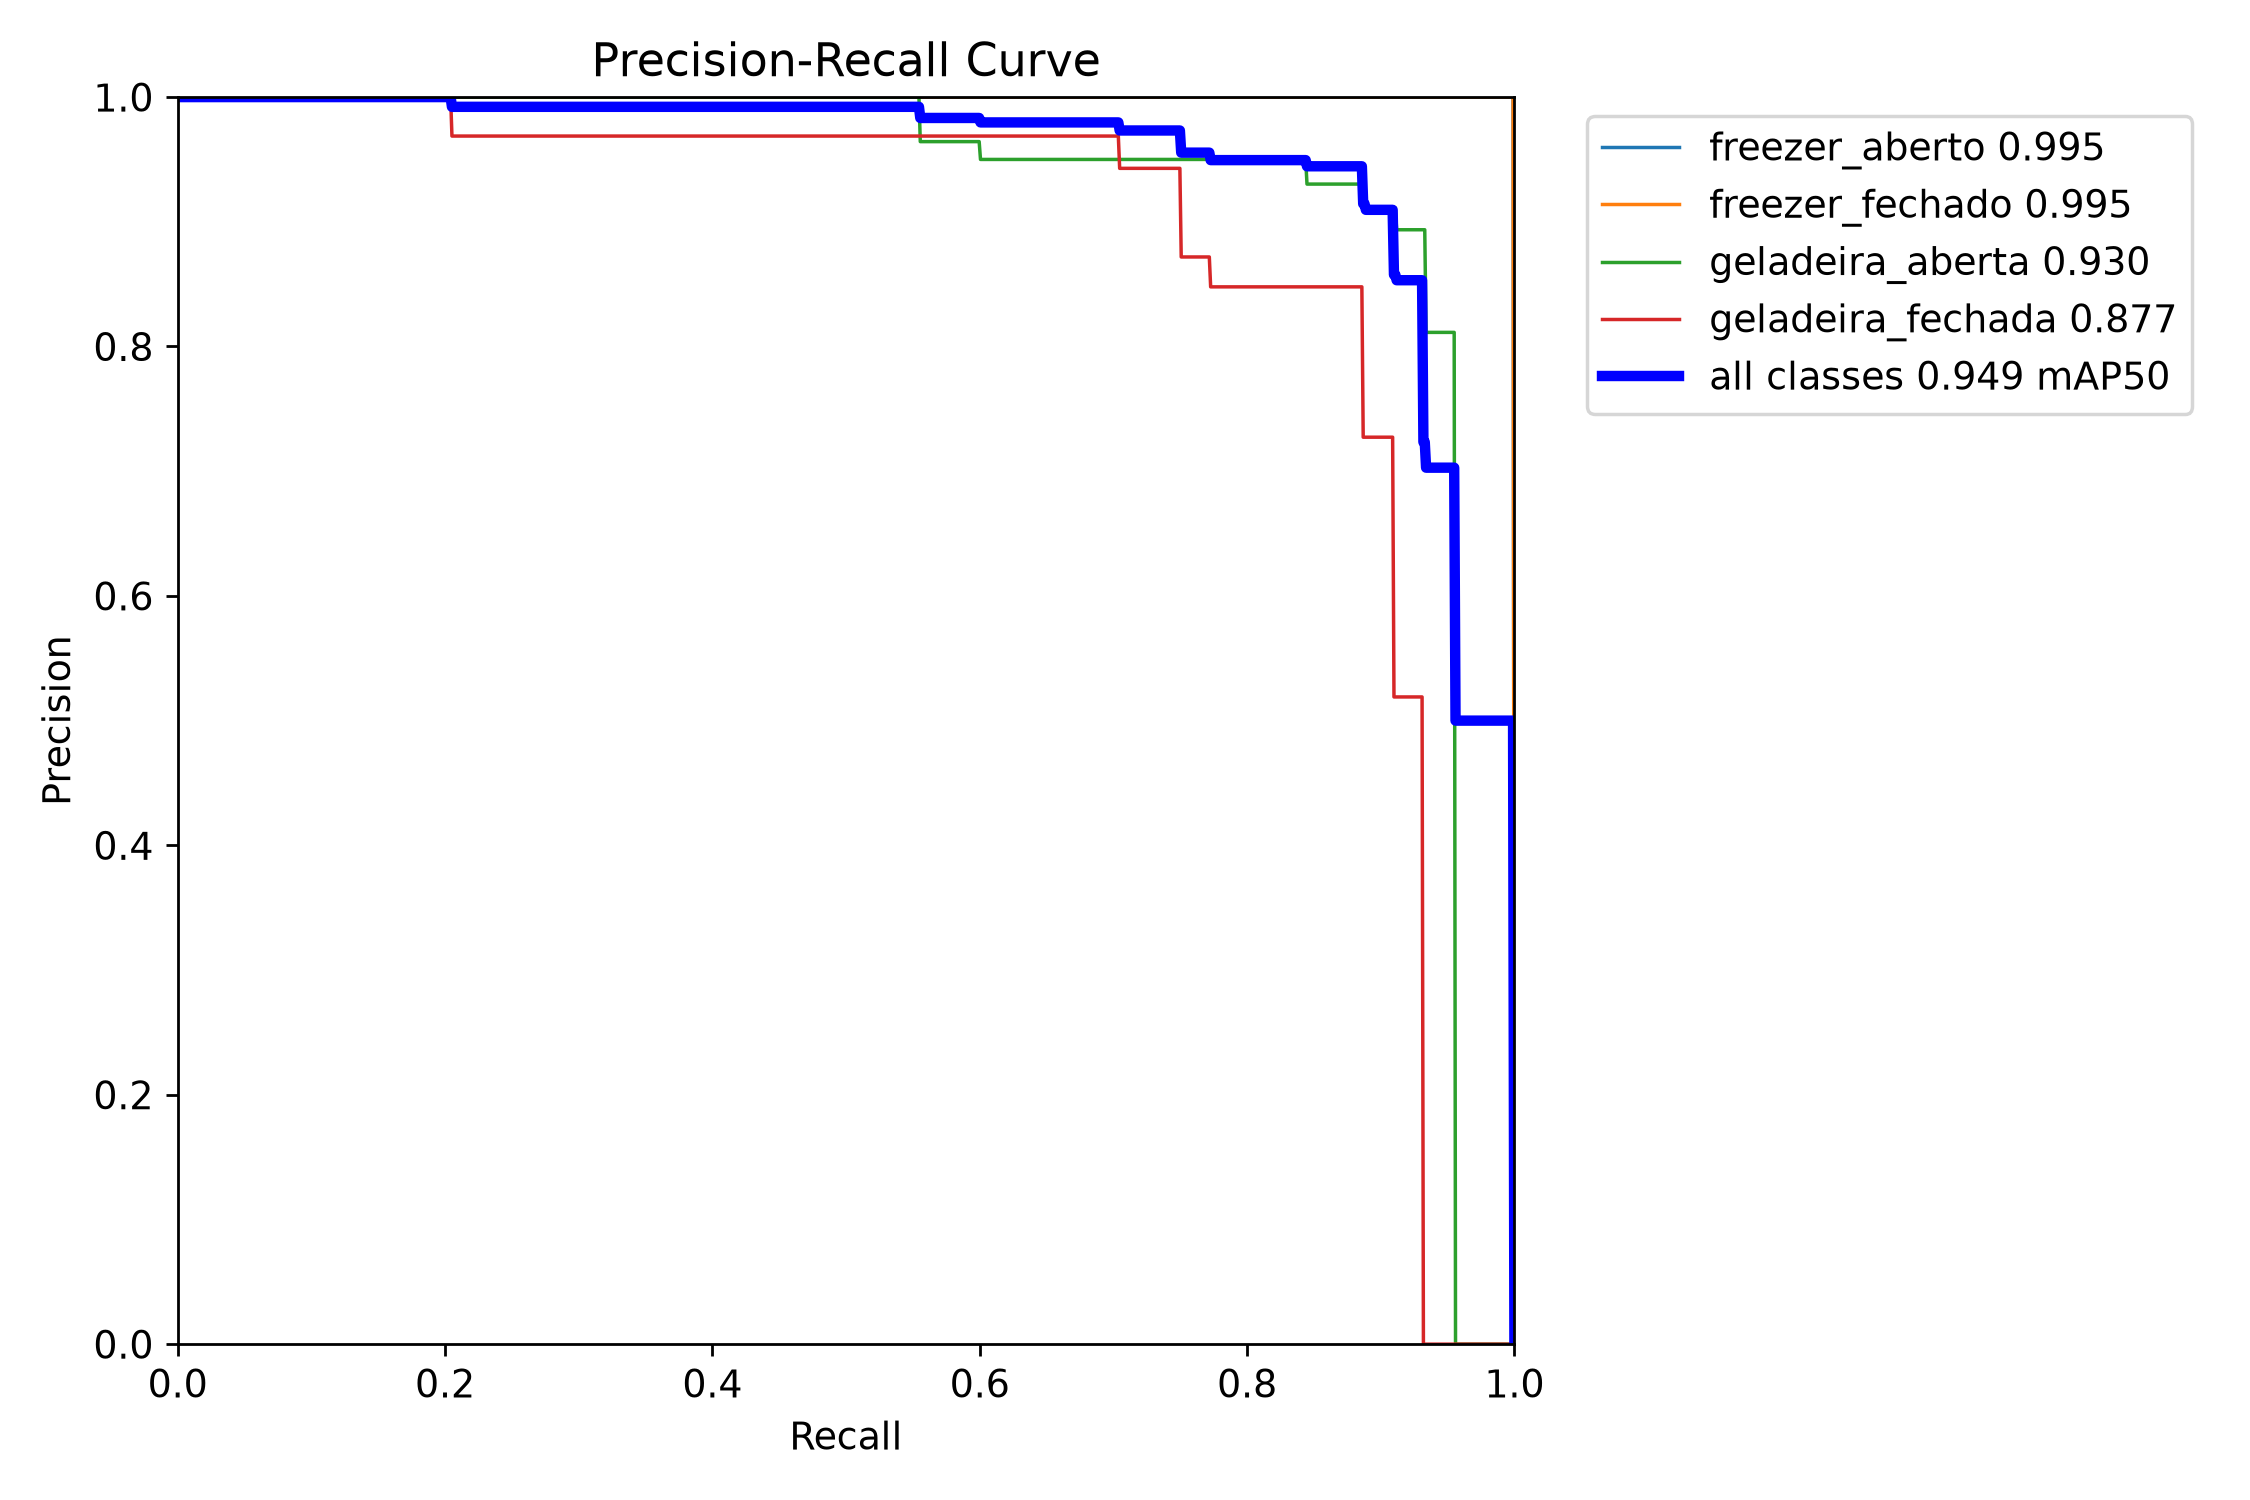

val_batch0_pred.jpg


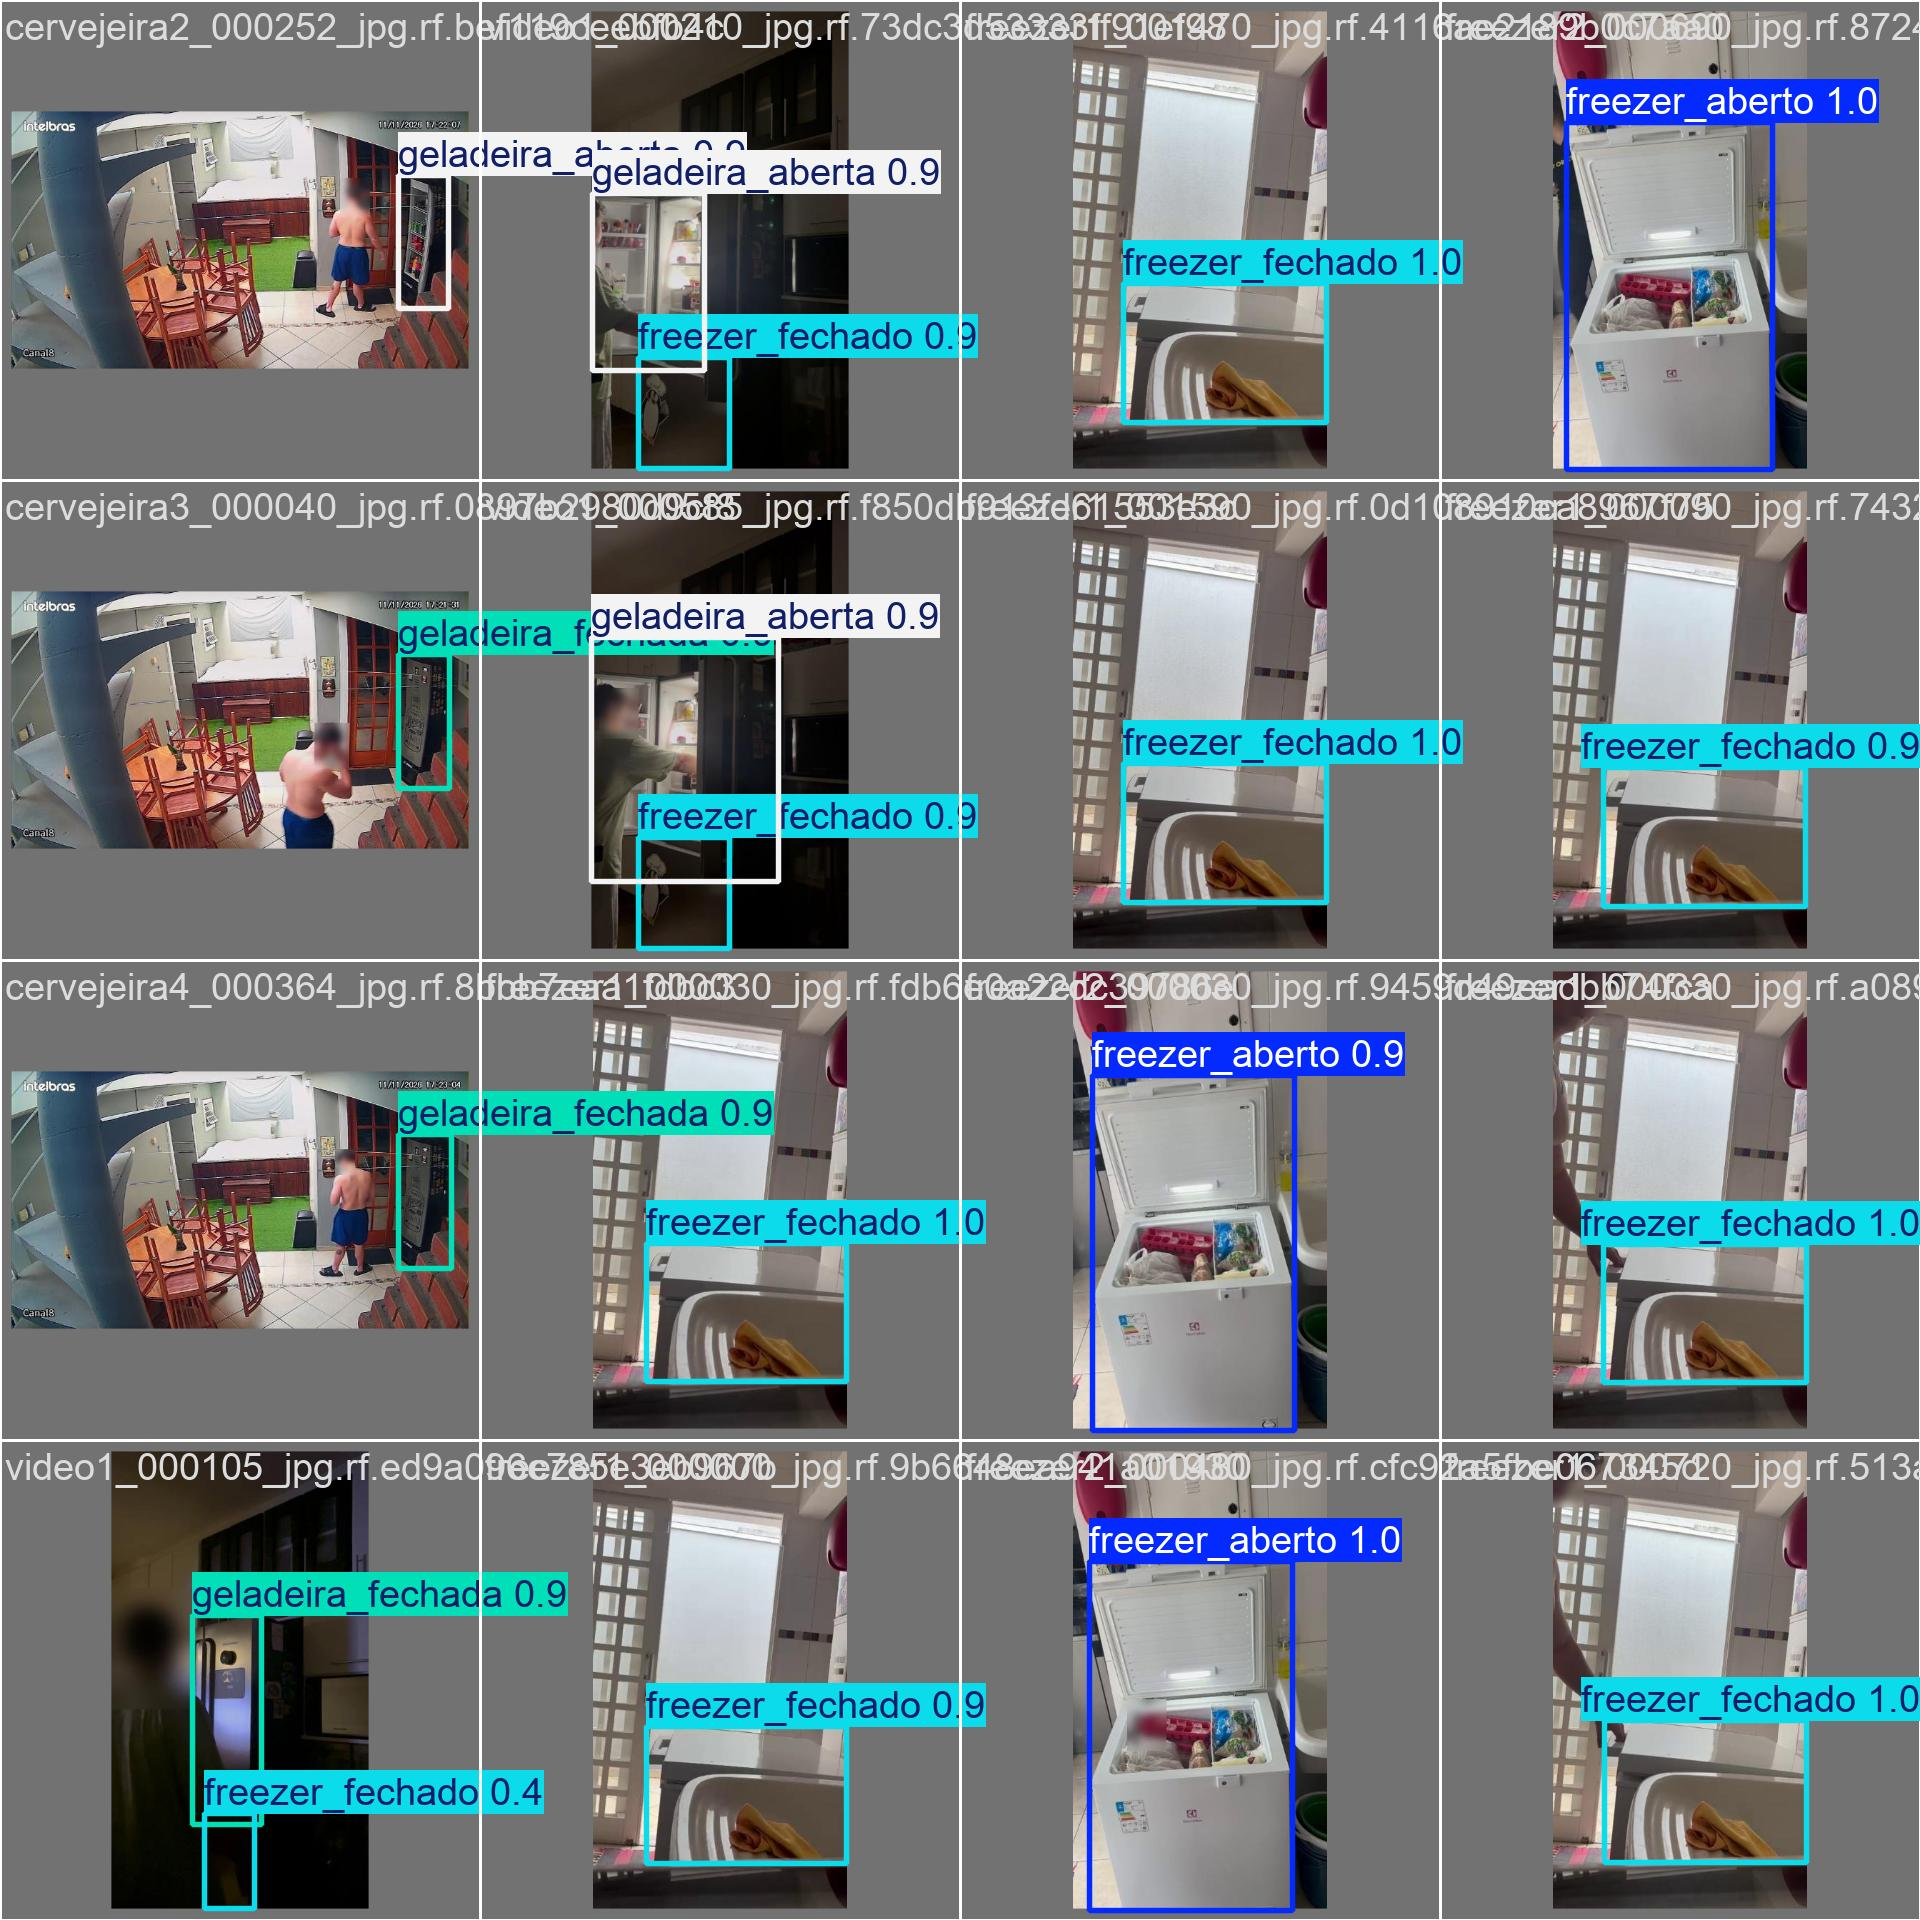

In [5]:
from IPython.display import Image, display

GRAFICOS = ["results.png", "confusion_matrix_normalized.png", "confusion_matrix.png",
            "BoxPR_curve.png", "PR_curve.png", "val_batch0_pred.jpg"]
for nome in GRAFICOS:
    arquivo = PASTA_TREINO / nome
    if arquivo.exists():
        print(nome)
        display(Image(filename=str(arquivo), width=900))

## 5. Avaliação no conjunto de teste

O conjunto de teste não foi usado no treino. Estes são os números que vão para o relatório:

- **Precisão:** das detecções feitas, quantas estavam certas.
- **Recall:** dos objetos que existiam, quantos o modelo encontrou.
- **mAP50** e **mAP50-95:** qualidade geral da detecção (quanto maior, melhor; o máximo é 1).

In [6]:
melhor = YOLO(str(MELHOR))
DIVISAO = "test" if "test" in dados else "val"
metricas = melhor.val(
    data=str(DATA_YAML),
    split=DIVISAO,
    imgsz=TAMANHO,
    project=str(RAIZ / "runs"),
    name=f"porta_{VERSAO}_{DIVISAO}",
    exist_ok=True,
    workers=TRABALHADORES,
)

tempo_ms = sum(float(v) for v in metricas.speed.values())
resumo = {
    "versao": VERSAO,
    "divisao": DIVISAO,
    "precisao": round(float(metricas.box.mp), 4),
    "recall": round(float(metricas.box.mr), 4),
    "mAP50": round(float(metricas.box.map50), 4),
    "mAP50_95": round(float(metricas.box.map), 4),
    "por_classe": {
        metricas.names[int(classe)]: {
            "mAP50": round(float(metricas.box.ap50[i]), 4),
            "mAP50_95": round(float(metricas.box.ap[i]), 4),
        }
        for i, classe in enumerate(metricas.box.ap_class_index)
    },
    "tempo_por_imagem_ms": round(tempo_ms, 2),
    "quadros_por_segundo": round(1000 / tempo_ms, 1) if tempo_ms else None,
    "epocas_pedidas": EPOCAS,
    "tamanho_imagem": TAMANHO,
}
print(json.dumps(resumo, indent=2, ensure_ascii=False))

Ultralytics 8.4.210  Python-3.13.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 3.7±1.1 MB/s, size: 20.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Natan\Documents\gs-energia\energia-acv\data\dataset\test\labels... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 1.4Kit/s 0.0s
val: New cache created: C:\Users\Natan\Documents\gs-energia\energia-acv\data\dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 5.8it/s 0.5s0.4s
                   all         48         74      0.965      0.914      0.955      0.813
        freezer_aberto          3          3      0.958          1      0.995      0.995
       freezer

## 6. Exemplos de detecção em imagens de teste

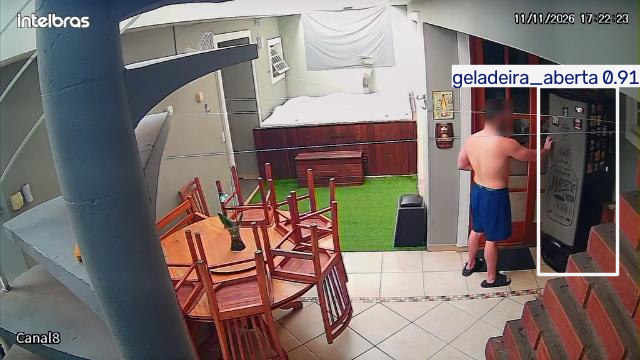

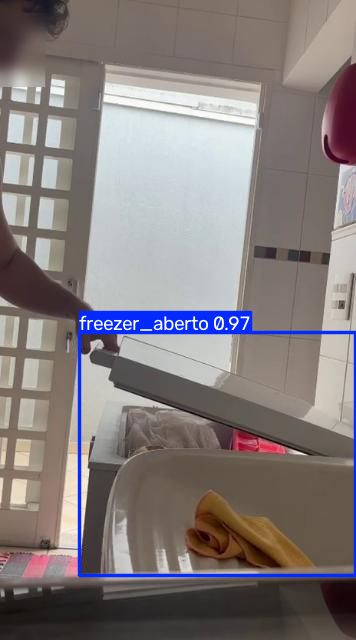

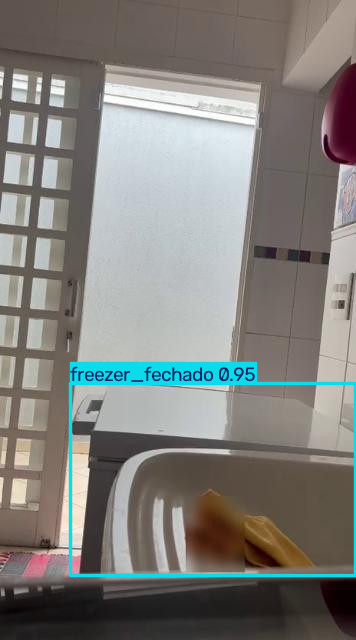

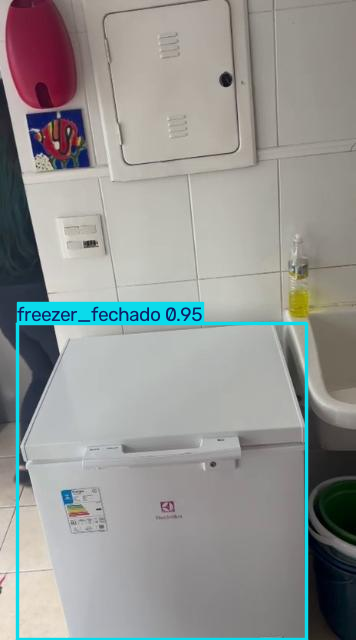

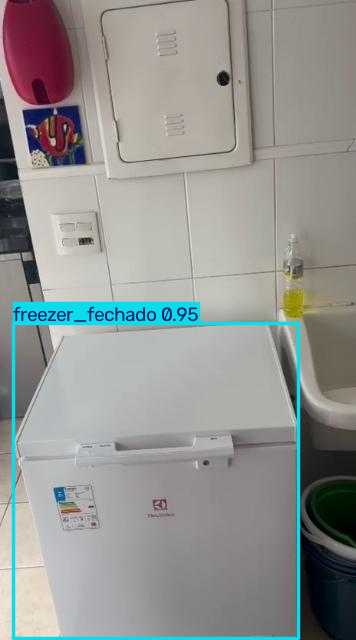

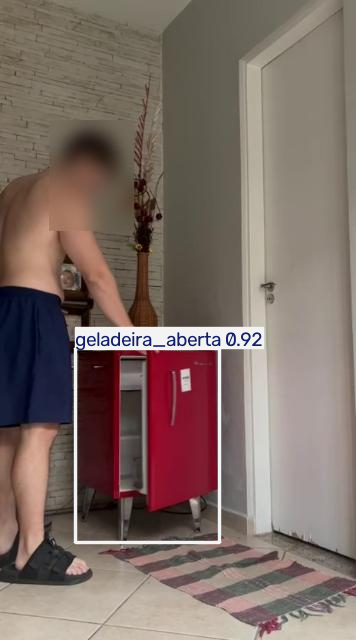

In [7]:
from PIL import Image as ImagemPIL

amostras = sorted((DATASET / dados[DIVISAO]).glob("*"))[:6]
for resultado in melhor.predict(amostras, conf=0.5, imgsz=TAMANHO, verbose=False):
    display(ImagemPIL.fromarray(resultado.plot()[:, :, ::-1]))

## 7. Guardar o modelo e os resultados

Copia os melhores pesos para `models/best.pt` (o arquivo que a aplicação usa) e os gráficos e métricas
para `results/<versão>/`, que vão para o repositório e para o relatório.

In [8]:
RESULTADOS = RAIZ / "results" / VERSAO
RESULTADOS.mkdir(parents=True, exist_ok=True)
(RESULTADOS / "metricas.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
for nome in GRAFICOS:
    if (PASTA_TREINO / nome).exists():
        shutil.copy2(PASTA_TREINO / nome, RESULTADOS / nome)

(RAIZ / "models").mkdir(exist_ok=True)
shutil.copy2(MELHOR, RAIZ / "models" / "best.pt")
print("Modelo salvo em", RAIZ / "models" / "best.pt")
print("Resultados salvos em", RESULTADOS)

if NO_COLAB:
    from google.colab import files

    shutil.make_archive("/content/resultados", "zip", RAIZ, "results")
    files.download(str(RAIZ / "models" / "best.pt"))
    files.download("/content/resultados.zip")

Modelo salvo em c:\Users\Natan\Documents\gs-energia\energia-acv\models\best.pt
Resultados salvos em c:\Users\Natan\Documents\gs-energia\energia-acv\results\v1


## 8. Comparação entre versões

Depois de treinar a `v2`, esta célula mostra as versões lado a lado. Essa comparação entra na
metodologia do relatório.

In [ ]:
print(f"{'Versão':<8}{'Divisão':<9}{'Precisão':>10}{'Recall':>9}{'mAP50':>8}{'mAP50-95':>10}{'ms/imagem':>11}")
for arquivo in sorted((RAIZ / "results").glob("*/metricas.json")):
    m = json.loads(arquivo.read_text(encoding="utf-8"))
    print(f"{m['versao']:<8}{m['divisao']:<9}{m['precisao']:>10.3f}{m['recall']:>9.3f}"
          f"{m['mAP50']:>8.3f}{m['mAP50_95']:>10.3f}{m['tempo_por_imagem_ms']:>11.1f}")